# EMA filtresi, adım adım inceleme

Tek bir EMA (üstel hareketli ortalama, exponential moving average) katı, birinci dereceden bir IIR alçak geçiren filtredir: $y[n] = y[n-1] + \alpha\,(x[n] - y[n-1])$. Bu, SR860/MFLI demodülatörlerindeki zaman sabiti filtresinin yapı taşıdır.

$\alpha$ doğrudan ayarlanmaz — bunun yerine bir zaman sabiti $\tau$ seçersin ve $\alpha = 1 - e^{-T_s/\tau}$ bunu verilen örnekleme periyodu $T_s$ için çevirir. Bu defter, `ema_float.py`'yi teorinin öngördüğü iki kapalı form sonuçla karşılaştırır: basamak yanıtı ve -3 dB bant genişliği.

In [1]:
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from ema_float import alpha_from_tau, ema_filter, f3db

## Basamak yanıtı ve analitik $1 - e^{-t/\tau}$

Birinci dereceden bir alçak geçiren filtreye birim basamak vermek, bir RC devresinin dolması gibi, $1 - e^{-t/\tau}$ eğrisini izleyerek 1'e doğru yükselmeli. Aşağıdaki `Ts` ve `tau` yer tutucudur — bu netleşince gerçek ADC hızını ve temsili bir zaman sabitini yaz.

alpha = 0.001


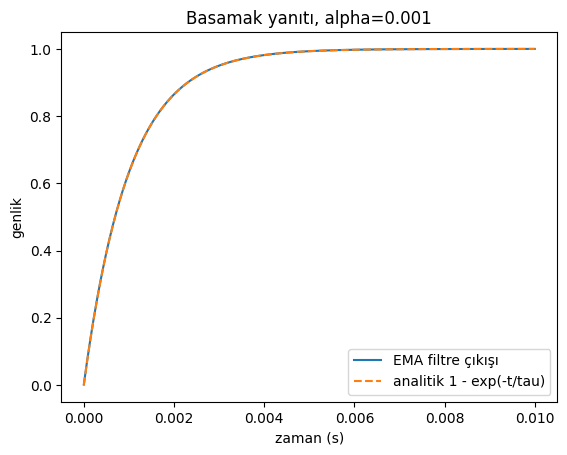

In [2]:
Ts = 1e-6   # yer tutucu örnekleme periyodu
tau = 1e-3  # yer tutucu zaman sabiti

alpha = alpha_from_tau(tau, Ts)
print(f'alpha = {alpha:.3g}')

n_samples = int(10 * tau / Ts)
t = np.arange(n_samples) * Ts
x = np.ones(n_samples)
y = ema_filter(x, alpha)

plt.plot(t, y, label='EMA filtre çıkışı')
plt.plot(t, 1 - np.exp(-t / tau), '--', label='analitik 1 - exp(-t/tau)')
plt.xlabel('zaman (s)')
plt.ylabel('genlik')
plt.legend()
plt.title(f'Basamak yanıtı, alpha={alpha:.3g}')
plt.show()

## Frekans yanıtı ve teorik -3 dB noktası

Tek bir kat için ($n = 1$), $f_{3\mathrm{dB}} = \frac{\sqrt{2^{1/1} - 1}}{2\pi\tau} = \frac{1}{2\pi\tau}$. Filtrenin gerçek frekans yanıtını `scipy.signal.freqz` ile hesaplayıp o frekanstaki genliğe bakmak tam -3 dB çıkmalı.

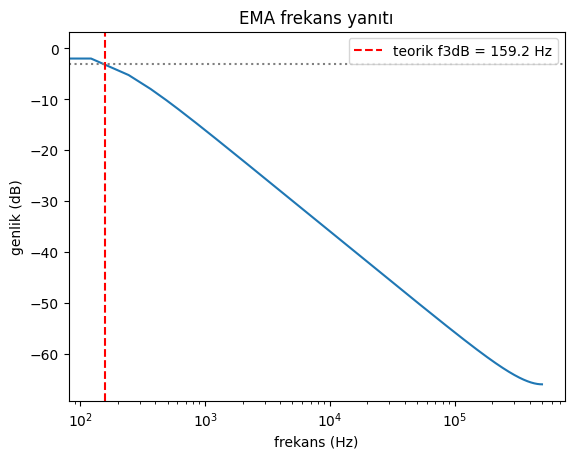

teorik f3dB noktasındaki genlik: -3.010 dB (-3.0 değerine yakın olmalı)


In [3]:
# y[n] = (1-alpha) y[n-1] + alpha x[n]
b, a = [alpha], [1, -(1 - alpha)]
w, h = signal.freqz(b, a, worN=4096, fs=1 / Ts)

f3db_theory = f3db(tau, n=1)
mag_at_f3db = 20 * np.log10(np.abs(signal.freqz(b, a, worN=[f3db_theory], fs=1 / Ts)[1][0]))

plt.semilogx(w, 20 * np.log10(np.abs(h)))
plt.axvline(f3db_theory, color='r', linestyle='--', label=f'teorik f3dB = {f3db_theory:.1f} Hz')
plt.axhline(-3, color='gray', linestyle=':')
plt.xlabel('frekans (Hz)')
plt.ylabel('genlik (dB)')
plt.legend()
plt.title('EMA frekans yanıtı')
plt.show()

print(f'teorik f3dB noktasındaki genlik: {mag_at_f3db:.3f} dB (-3.0 değerine yakın olmalı)')

## $\tau$ nasıl seçilir?

**$\alpha$ ve $\tau$ ne demek.** Filtre her örnekte, çıkışı ile girişi arasındaki farkın sabit bir kesrini kapatır: $y \leftarrow y + \alpha\,(x - y)$. Bu kesir $\alpha$'dır. $\tau$ aynı şeyin saniye cinsinden ölçüsüdür: *farkın %63'ünü kapatmak için geçen süre* ($1 - 1/e$). $\alpha = 1 - e^{-T_s/\tau}$ dönüşümü, ayrık filtrenin analog RC eğrisini örnekleme anlarında birebir üretmesini sağlar. $\alpha = T_s/\tau$ kısayolu ancak $T_s$, $\tau$'dan çok küçükken çalışır: $T_s = \tau$ olduğunda $\alpha = 1$ verir (filtre girişi aynen kopyalar), oysa doğru değer $0.632$'dir.

**$\tau$ bir tasarım kararıdır, sinyalden hesaplanan bir şey değildir.** Onu üç gereksinimden seçersin ve bu her zaman aralarında bir takastır:

| $\tau$ büyürse | etki |
|---|---|
| $f_{3\mathrm{dB}} = \frac{1}{2\pi\tau}$ düşer | istenmeyen frekanslar (girişim, gürültü) daha çok zayıflatılır |
| çıkış daha yavaş oturur | bir basamağın %1'ine ulaşmak yaklaşık $4.6\,\tau$, %5'ine ulaşmak yaklaşık $3\tau$ sürer |
| daha az gürültü geçer | tek katın gürültü bant genişliği $\frac{\pi}{2}\,f_{3\mathrm{dB}}$'dir; bu yüzden gürültü rms değeri $\sqrt{f_{3\mathrm{dB}}}$ ile düşer |
| $\alpha$ küçülür | yüksek örnekleme hızında biriktiricinin duraksamasına ve koruma biti (guard bit) gerektirmesine yol açan budur (bkz. `ema_fixed_exploration_tr.ipynb`) |

**İşe yarayan bir yöntem:**

1. Korumak istediğin frekansı (sinyal) ve bastırmak istediğin frekansı (girişim) yaz.
2. Her biri için ne kadar zayıflama istediğini söyle: örneğin "sinyalde en çok 1 dB kayıp, girişimde en az 20 dB".
3. Tek katın $f$ frekansındaki zayıflaması $-10 \log_{10}\!\left(1 + (f/f_{3\mathrm{dB}})^2\right)$ değeridir. İkisini birden sağlayan $f_{3\mathrm{dB}}$ aralığını çöz.
4. Dönüştür: $\tau = \frac{1}{2\pi f_{3\mathrm{dB}}}$, sonra $\alpha = 1 - e^{-T_s/\tau}$.
5. Oturma süresinin kabul edilebilir olduğunu kontrol et ($\approx 4.6\,\tau$).

Sonraki hücre, aşağıda kullanılan örnek için 3. adımı yapar: 10 Hz'i koru (≤ 1 dB kayıp), 100 Hz'i bastır (≥ 20 dB).

10 Hz korunacak (en çok 1 dB kayıp), 100 Hz bastırılacak (en az 20 dB)

   kat          kat başına f3dB >=      ve <=   sonuç
     1                     19.7 Hz    10.1 Hz   Bu kat sayısıyla İMKANSIZ
     2                     28.6 Hz    33.3 Hz   OK: f3dB'yi [28.6, 33.3] Hz aralığından seç
     3                     35.4 Hz    52.4 Hz   OK: f3dB'yi [35.4, 52.4] Hz aralığından seç
     4                     41.1 Hz    68.0 Hz   OK: f3dB'yi [41.1, 68.0] Hz aralığından seç


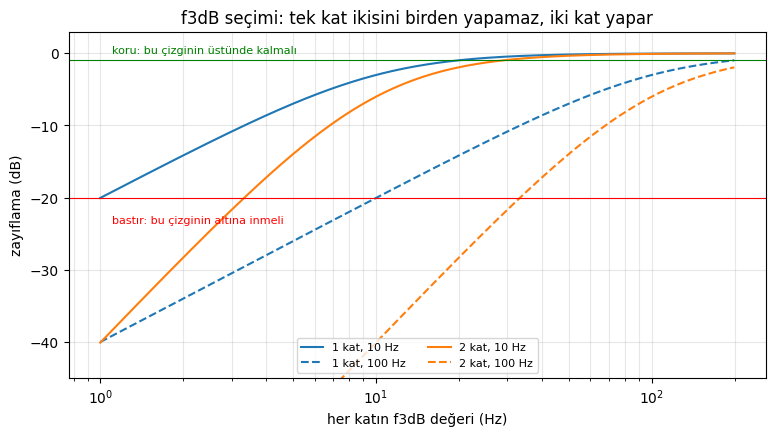

In [4]:
f_keep, f_reject = 10.0, 100.0
max_loss_keep, min_atten_reject = 1.0, 20.0        # dB

print(f"{f_keep:g} Hz korunacak (en çok {max_loss_keep:g} dB kayıp), {f_reject:g} Hz bastırılacak (en az {min_atten_reject:g} dB)\n")
print(f"{'kat':>6} {'kat başına f3dB >=':>27} {'ve <=':>10}   sonuç")
for n in (1, 2, 3, 4):
    # n özdeş kat: zayıflama = -10*n*log10(1 + (f/fc)^2)
    lo = f_keep / np.sqrt(10 ** (max_loss_keep / (10 * n)) - 1)
    hi = f_reject / np.sqrt(10 ** (min_atten_reject / (10 * n)) - 1)
    verdict = f"OK: f3dB'yi [{lo:.1f}, {hi:.1f}] Hz aralığından seç" if lo <= hi else "Bu kat sayısıyla İMKANSIZ"
    print(f"{n:>6} {lo:>24.1f} Hz {hi:>7.1f} Hz   {verdict}")

fc = np.logspace(0, 2.3, 400)                       # kat başına köşe frekansı, 1 .. 200 Hz
fig, ax = plt.subplots(figsize=(9, 4.5))
for n, color in ((1, 'tab:blue'), (2, 'tab:orange')):
    for f, ls in ((f_keep, '-'), (f_reject, '--')):
        ax.plot(fc, -10 * n * np.log10(1 + (f / fc) ** 2), ls, color=color, label=f'{n} kat, {f:g} Hz')
ax.axhline(-max_loss_keep, color='green', lw=0.8)
ax.axhline(-min_atten_reject, color='red', lw=0.8)
ax.text(1.1, -max_loss_keep + 1, 'koru: bu çizginin üstünde kalmalı', color='green', fontsize=8)
ax.text(1.1, -min_atten_reject - 3.5, 'bastır: bu çizginin altına inmeli', color='red', fontsize=8)
ax.set_xscale('log')
ax.set_ylim(-45, 3)
ax.set_xlabel('her katın f3dB değeri (Hz)')
ax.set_ylabel('zayıflama (dB)')
ax.set_title('f3dB seçimi: tek kat ikisini birden yapamaz, iki kat yapar')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8, ncol=2, loc='lower center')
plt.show()

Bunu nasıl okumalı:

- Düz çizgi (10 Hz) yeşil çizginin **üstünde** kalmalı, kesikli çizgi (100 Hz) kırmızı çizginin **altına** inmeli. İkisinin birden sağlandığı $f_{3\mathrm{dB}}$ değerleri cevaptır.
- **Tek katın cevabı yok.** 10 Hz'i 1 dB içinde korumak için $f_{3\mathrm{dB}} \geq 19.7\ \text{Hz}$ gerekir; 100 Hz'i 20 dB bastırmak için $f_{3\mathrm{dB}} \leq 10.1\ \text{Hz}$ gerekir. İki aralık kesişmez. Bu, birinci dereceden bir filtrenin yatışıdır (roll-off): dekad başına sadece 20 dB; bu yüzden bir dekad arayla duran tonları ayıramaz *ve* istenen tonu bozmadan bırakamaz.
- **İki kat yapar:** her katın $[28.6,\ 33.3]$ Hz aralığında olması işe yarar. Lock-in yükselteçlerinin 6/12/18/24 dB/oktav eğimleri sunmasının nedeni budur; bunlar 1 ila 4 art arda bağlı kattır. Önce birini boyutlandır, sonra gereksinim sağlanana kadar kat ekle.
- Sonraki bölümdeki tablo, tek kat için, birkaç $f_{3\mathrm{dB}}$ değerinde aynı alıştırmadır.

## İki tonlu örnek: 10 Hz'i 100 Hz'den ayırmak

Öncekiyle aynı fikir, sadece 10 kat yukarı kaydırılmış (hâlâ bir dekad ayrım var, yani aynı takas şekli tekrar eder; $\tau$ buna uymak için 10 kat küçülür):

| f3dB | tau | 10 Hz'deki zayıflama | 100 Hz'deki zayıflama |
|---|---|---|---|
| 5 Hz | 31.8 ms | -6.99 dB | -26.0 dB |
| 10 Hz | 15.9 ms | -3.01 dB | -20.0 dB |
| 20 Hz | 8.0 ms | -0.97 dB | -14.2 dB |
| 30 Hz | 5.3 ms | -0.46 dB | -10.8 dB |
| 50 Hz | 3.2 ms | -0.17 dB | -7.0 dB |

Orta yol olarak $f_{3\mathrm{dB}} = 20\ \text{Hz}$ seçilirse: 10 Hz neredeyse hiç etkilenmeden geçer (-1 dB), 100 Hz ise yaklaşık -14 dB bastırılır (orijinal genliğinin ~%20'si).

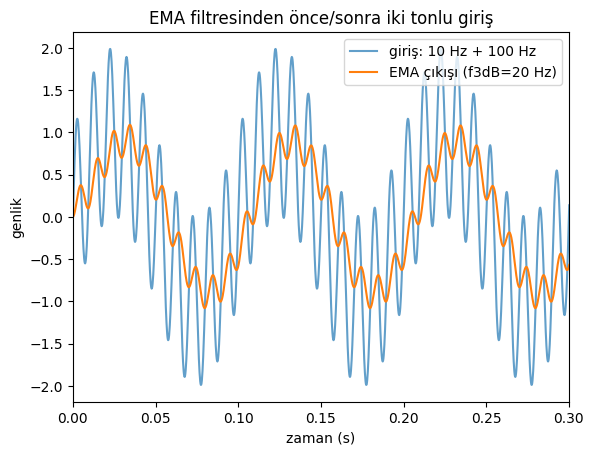

In [5]:
Fs = 5000.0          # demo örnekleme hızı, gerçek ADC hızından bağımsız (henüz yanıtlanmadı)
duration = 1.0       # 1 Hz FFT çözünürlüğü; 10/100 Hz tonları tam bin'lere oturur
t_demo = np.arange(0, duration, 1 / Fs)
x_tone = np.sin(2 * np.pi * 10 * t_demo) + np.sin(2 * np.pi * 100 * t_demo)

f3db_choice = 20.0   # yukarıdaki tablodan orta yol seçimi
tau_choice = 1 / (2 * np.pi * f3db_choice)
alpha_choice = alpha_from_tau(tau_choice, 1 / Fs)
y_tone = ema_filter(x_tone, alpha_choice)

plt.plot(t_demo, x_tone, label='giriş: 10 Hz + 100 Hz', alpha=0.7)
plt.plot(t_demo, y_tone, label=f'EMA çıkışı (f3dB={f3db_choice:.0f} Hz)')
plt.xlim(0, 0.3)
plt.xlabel('zaman (s)')
plt.ylabel('genlik')
plt.legend()
plt.title('EMA filtresinden önce/sonra iki tonlu giriş')
plt.show()

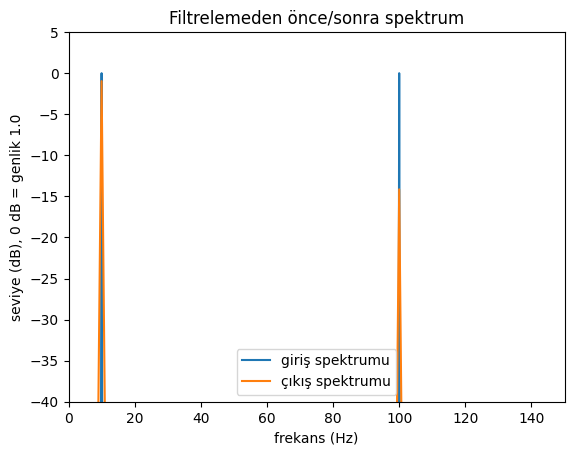

 10 Hz: ölçülen zayıflama =  -0.97 dB, teori =  -0.97 dB
100 Hz: ölçülen zayıflama = -14.14 dB, teori = -14.15 dB


In [6]:
scale = len(x_tone) / 2           # birim genlikli sinüs |FFT| = N/2 verir; bölünce 1.0 = 0 dB okunur
X = np.fft.rfft(x_tone) / scale
Y = np.fft.rfft(y_tone) / scale
freqs = np.fft.rfftfreq(len(x_tone), d=1 / Fs)

plt.plot(freqs, 20 * np.log10(np.abs(X) + 1e-12), label='giriş spektrumu')
plt.plot(freqs, 20 * np.log10(np.abs(Y) + 1e-12), label='çıkış spektrumu')
plt.xlim(0, 150)
plt.ylim(-40, 5)  # yakınlaştır: diğer bin'ler ~kayan nokta sıfırı (-200+ dB),
                  # aksi halde gerçek tepeleri üstteki ince bir şeride sıkıştırırdı
plt.xlabel('frekans (Hz)')
plt.ylabel('seviye (dB), 0 dB = genlik 1.0')
plt.legend()
plt.title('Filtrelemeden önce/sonra spektrum')
plt.show()

for f in [10, 100]:
    k = int(round(f * duration))
    measured_db = 20 * np.log10(np.abs(Y[k]) / np.abs(X[k]))
    theory_db = -10 * np.log10(1 + (f / f3db_choice) ** 2)
    print(f'{f:>3} Hz: ölçülen zayıflama = {measured_db:6.2f} dB, teori = {theory_db:6.2f} dB')

### Sayıları okumak: bu dB değerleri ne anlama geliyor?

Her giriş tonunun genliği 1.0'dır, yani grafikte **0 dB**'de durur. Filtreden sonra:

| ton | sonraki seviye | genlik oranı | anlamı |
|---|---|---|---|
| 10 Hz | -0.97 dB | 0.894 | istenen ton genliğinin yaklaşık %11'ini kaybeder |
| 100 Hz | -14.1 dB | 0.196 | istenmeyen ton genliğinin yaklaşık %20'sine düşer |

- **Genlik oranı $10^{\text{dB}/20}$'dir.** -14 dB, $10^{-14/20} = 0.2$ eder. Referans değerler: -6 dB yarısı, -20 dB onda biri, -40 dB yüzde biri.
- **Burada sadece fark anlamlıdır.** Bu grafiğin önceki halinde tepeler yaklaşık 68 dB'de duruyor ve yaklaşık 54 dB'ye düşüyordu. 68, sinyalden değil FFT'nin kendi ölçeğinden geliyordu (birim bir sinüs $|\mathrm{FFT}| = N/2 = 2500$ verir ve $20 \log_{10}(2500) = 68$). Gerçek bilgi 14 dB'lik düşüştür; grafik artık $N/2$'ye böler, böylece birim bir ton dsp02 spektrum grafiklerindeki gibi 0 dB okunur.
- **Kat sayısı arttıkça dB'ler toplanır.** İki özdeş kat dB'nin iki katını verir: -14 dB, -28 dB olur (genlik 0.04).
- **Bir ölçüm için ne anlama gelir.** Zayıflama ancak girişimin ne kadar büyük olduğuyla kıyaslandığında işe yarar. 100 Hz girişimi sinyalinden 10 kat büyükse (+20 dB) ve 14 dB bastırırsan, hâlâ sinyalinden 2 kat büyüktür (+6 dB). Onu sinyalin %10'una indirmek için $20\ \text{dB} + 20\ \text{dB} = 40\ \text{dB}$ zayıflama gerekir. Yani gereken zayıflamayı girişimin sinyale **oranından** belirle, sonra kat sayısını ve $f_{3\mathrm{dB}}$ değerini bulmak için "$\tau$ nasıl seçilir?" bölümündeki yöntemi kullan.
- Ölçülen değerler, kapalı form teori $-10 \log_{10}\!\left(1 + (f/f_{3\mathrm{dB}})^2\right)$ ile 0.01 dB içinde uyuşur; yani formül sadece taranan tek bir sinüs için değil, gerçek iki tonlu bir sinyal için de geçerlidir.